# 4. Elastic net

$$\min_\beta \frac{1}{2n}\lVert y - X\beta\rVert^2 + \lambda\Big[\alpha\lVert\beta\rVert_1 + \tfrac{1-\alpha}{2}\lVert\beta\rVert_2^2\Big]$$

$\alpha$ (`l1_ratio` in scikit-learn) moves between ridge ($\alpha=0$) and the lasso ($\alpha=1$).
Zou and Hastie (2005) showed the ridge part produces a **grouping effect**: highly correlated
predictors get similar coefficients and enter or leave together, while the L1 part still gives
sparsity. It can also select more than $n$ variables.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## The grouping effect
Three near-copies of one signal, plus 20 noise variables.

In [2]:
from sklearn.linear_model import Lasso, ElasticNet
n = 80
z = rng.normal(size=n)
group = np.c_[[z + 0.1 * rng.normal(size=n) for _ in range(3)]].T
noise = rng.normal(size=(n, 20))
X = np.c_[group, noise]; X = (X - X.mean(0)) / X.std(0)
y = 3 * z + rng.normal(size=n)
print("lasso      :", np.round(Lasso(alpha=0.1).fit(X, y).coef_[:5], 2))
print("elastic net:", np.round(ElasticNet(alpha=0.1, l1_ratio=0.3).fit(X, y).coef_[:5], 2))

lasso      : [ 0.99  0.59  0.52 -0.   -0.  ]
elastic net: [ 0.71  0.7   0.71 -0.05 -0.  ]


The lasso puts most weight on one copy; the elastic net shares it across all three. In nowcasting,
the "copies" are things like total production, manufacturing and goods exports. Sharing weight
makes the model less dependent on any single series being revised or published late.

## Tuning two parameters
Cross-validate over a grid of $\alpha$ values and, for each, a path of $\lambda$ values.
`ElasticNetCV` does this; the project uses `l1_ratio` in {0.1, 0.3, 0.5, 0.7, 0.9, 0.99}.

In [3]:
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import KFold
m = ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.99], cv=KFold(5, shuffle=True, random_state=0)).fit(X, y)
print("chosen l1_ratio:", m.l1_ratio_, " lambda:", round(m.alpha_, 4))
mse = m.mse_path_.mean(axis=2)   # l1_ratio x alphas
for r, row in zip(m.l1_ratio, mse):
    print(f"l1_ratio={r:<5} best CV MSE={row.min():.3f}")

chosen l1_ratio: 0.7  lambda: 0.1937
l1_ratio=0.1   best CV MSE=1.102
l1_ratio=0.3   best CV MSE=1.061
l1_ratio=0.5   best CV MSE=1.037
l1_ratio=0.7   best CV MSE=1.037
l1_ratio=0.9   best CV MSE=1.059
l1_ratio=0.99  best CV MSE=1.082


(Shuffled K-fold is fine here only because these toy observations are independent. With time
series it leaks the future: see notebook 5.)

## On the project's data: is the selection stable?
The real design has 236 features: six monthly lags of each indicator, so every indicator is
itself a block of correlated columns. Refit the lasso and an elastic net ($\alpha = 0.5$) on 40
random subsamples of 80% of the quarters, with the project's blocked time-series folds, and
record which **indicators** (any lag) are selected each time.

In [4]:
# The project's real data: the horizon-2 design (nowcast made at the end of the quarter)
from nowcast.features import build_all, main_spec
from nowcast.models import Standardiser
B = build_all([2])
X = B["X"][2]
X = X[[c for c in X.columns if main_spec(c)]]       # real-time output + other indicators
y = B["first"].reindex(X.index)                      # target: ONS's first published estimate
keep = y.notna() & ~X.index.isin(pd.period_range("2020Q1", "2021Q2", freq="Q"))
X, y = X[keep], y[keep]
names = list(X.columns)
print(X.shape, "quarters x features")

(108, 236) quarters x features


In [5]:
from sklearn.linear_model import LassoCV
from nowcast.models import time_folds
Z = ((X - X.mean()) / X.std()).fillna(0).values
yv = y.values
ind = np.array([c.rsplit("_l", 1)[0] for c in names])
codes = pd.unique(ind)

def selected_indicators(coef):
    return set(ind[np.abs(coef) > 1e-10])

sel = {"Lasso": [], "Elastic net (0.5)": []}
for b in range(40):
    rows = np.sort(rng.choice(len(yv), int(0.8 * len(yv)), replace=False))   # keep time order
    Zb, yb = Z[rows], yv[rows]
    folds = time_folds(len(yb))
    sel["Lasso"].append(selected_indicators(LassoCV(cv=folds, max_iter=20000).fit(Zb, yb).coef_))
    sel["Elastic net (0.5)"].append(selected_indicators(
        ElasticNetCV(l1_ratio=0.5, cv=folds, max_iter=20000).fit(Zb, yb).coef_))

def mean_jaccard(sets):
    s = [len(a & b) / max(1, len(a | b)) for i, a in enumerate(sets) for b in sets[i + 1:]]
    return np.mean(s)

for k, sets in sel.items():
    print(f"{k:<18} indicators selected: median {np.median([len(s) for s in sets]):.0f}, "
          f"mean pairwise Jaccard similarity {mean_jaccard(sets):.2f}")

Lasso              indicators selected: median 16, mean pairwise Jaccard similarity 0.30
Elastic net (0.5)  indicators selected: median 18, mean pairwise Jaccard similarity 0.34


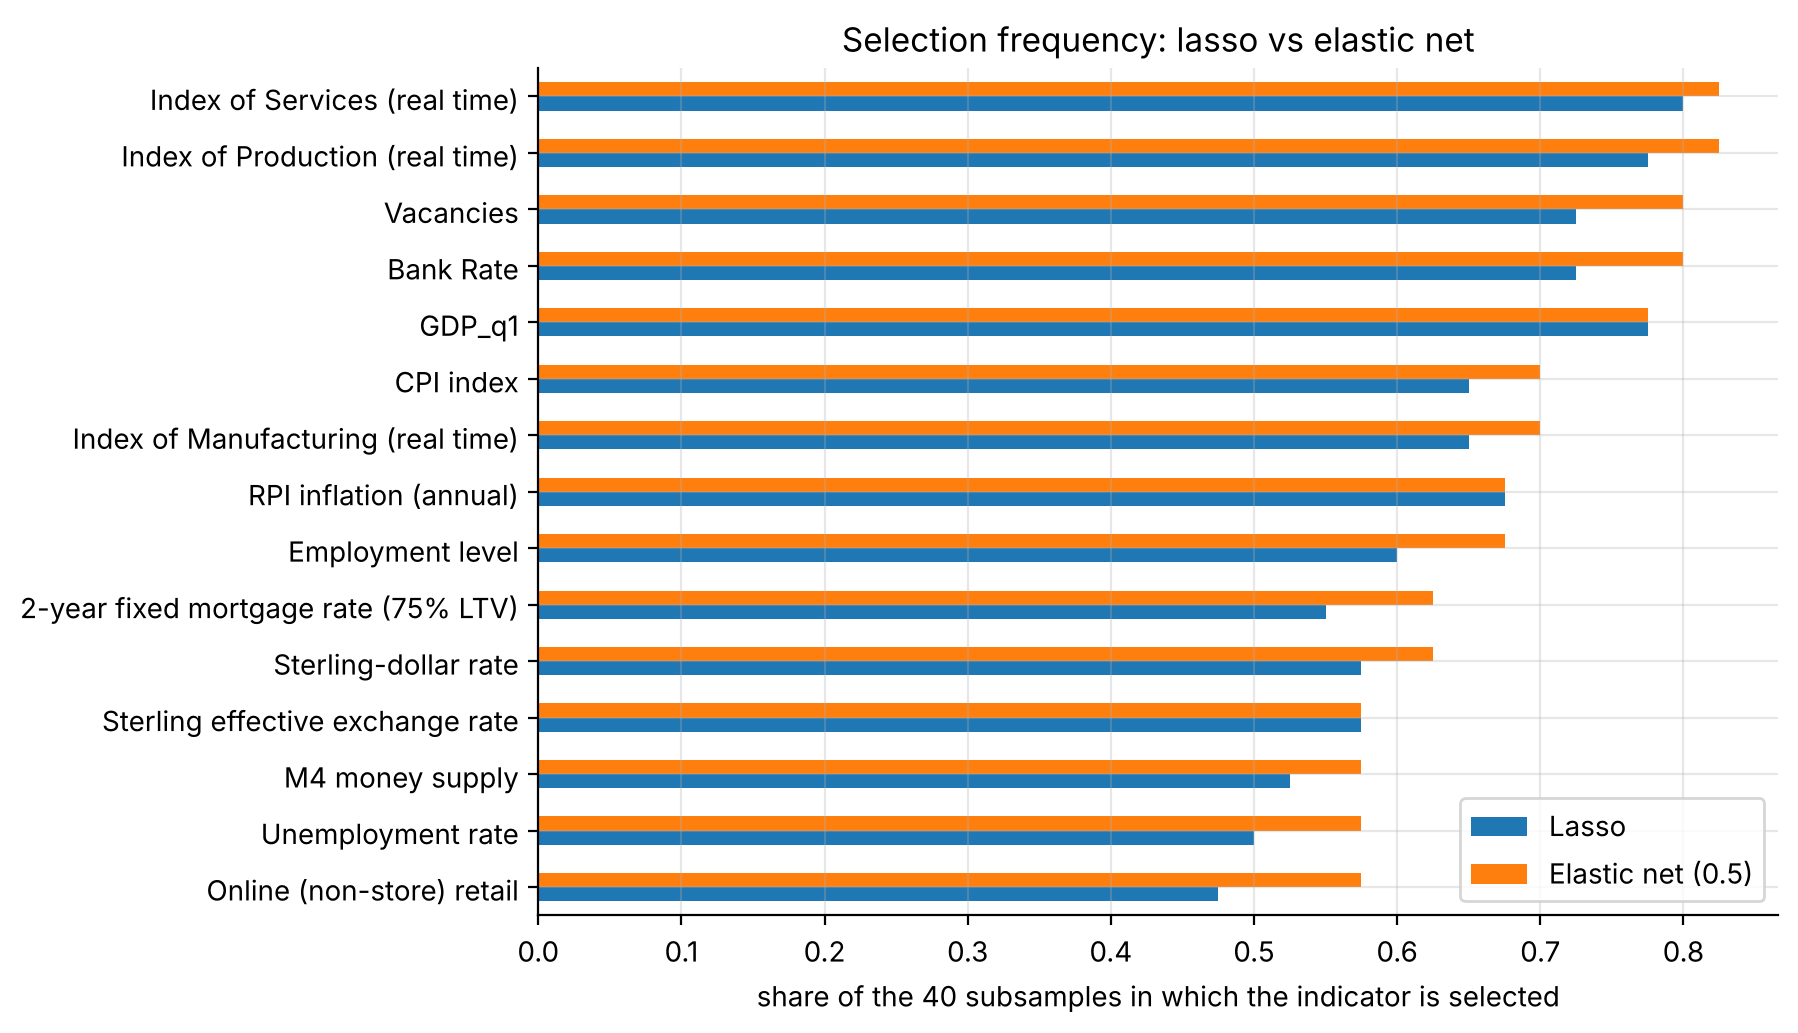

In [6]:
freq = pd.DataFrame({k: pd.Series([c for s in sets for c in s]).value_counts() / len(sets)
                     for k, sets in sel.items()}).fillna(0)
top = freq.max(axis=1).sort_values(ascending=False).head(15).index
from nowcast.config import INDICATOR_BY_CODE
labels = [INDICATOR_BY_CODE[c].name if c in INDICATOR_BY_CODE else c for c in top]
ax = freq.loc[top].set_axis(labels).iloc[::-1].plot.barh(figsize=(8, 5.5))
ax.set_xlabel("share of the 40 subsamples in which the indicator is selected")
ax.set_title("Selection frequency: lasso vs elastic net");

Read the chart as a stability check. Indicators near 1.0 are found in almost every subsample;
indicators near 0.2 are found only sometimes, usually because a correlated neighbour took their
place. The elastic net's ridge part tends to keep correlated indicators in together, and the lasso
tends to switch between them. That instability is why the project reports *groups* of indicators,
not individual lasso picks (see notebook 8 and `outputs/tables/selection_frequency.csv`).

**Key takeaways**
* Use the elastic net when predictors come in correlated blocks and you still want sparsity.
* Measure selection stability by refitting on subsamples. A single lasso fit's list of selected
  variables is not a finding.
* The extra tuning parameter costs computation, not much accuracy.